## Outliers and Skewness — Short Notes

Outliers

* Outliers are observations that differ significantly from the general pattern of a dataset. They may represent anomalies, measurement errors, or legitimate rare values.

* Outliers can affect Linear Regression, Logistic Regression, and some deep-learning models. Their impact depends on the model and loss function.

* Models that rely on distances or numerical optimization can be sensitive to extreme values. Tree-based models are generally less sensitive to feature outliers.

Skewness

* Skewness measures the asymmetry of a data distribution. >+1, <0

* Positive skew: Longer tail on the right.

* Negative skew: Longer tail on the left.

* Zero skewness: The distribution is approximately symmetric, though zero skewness alone does not guarantee normality.




```mermaid
flowchart
A[Outlier] -->B[Z-score] --> C[Trim,Cap]
A--> D[IQR] --> C
A --> E[Percentile] --> C
A --> F[Winerizaion] --> G[Cap using Percentile]

```

Detect Outlier and Skewness

In [213]:
import pandas as pd

pd.set_option('display.max_columns', None)
import  matplotlib.pyplot as plt
import  seaborn as sns

In [214]:
try:
    df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/tips.csv'



                     )
except Exception as e:
    print(e)

In [215]:
df.sample(5)

,total_bill,tip,sex,smoker,day,time,size
86,13.03,2.00,Male,No,Thur,Lunch,2
92,5.75,1.00,Female,Yes,Fri,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
56,38.01,3.00,Male,Yes,Sat,Dinner,4
242,17.82,1.75,Male,No,Sat,Dinner,2


In [216]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


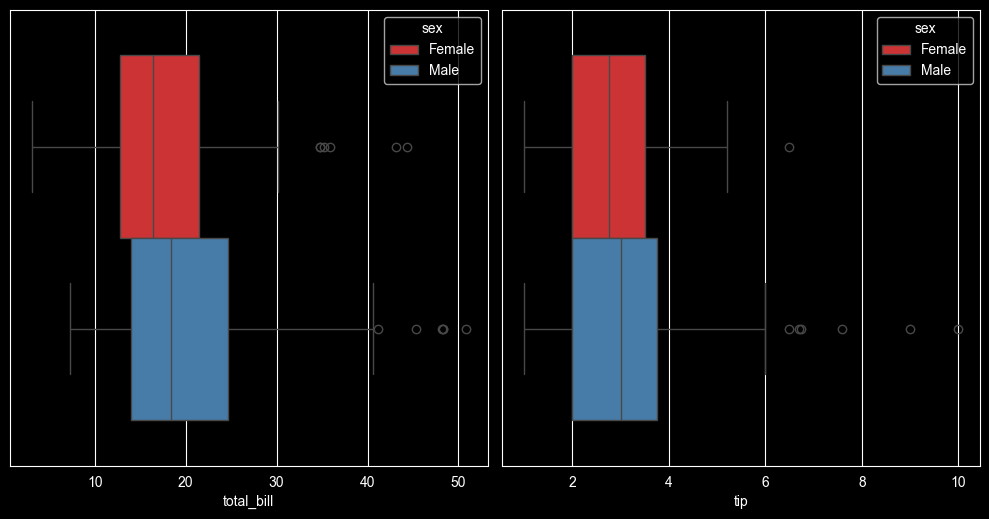

In [217]:
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
sns.boxplot(data=df, x='total_bill',hue='sex',palette='Set1')
plt.subplot(2,2,2)


plt.subplot(2,2,2)
sns.boxplot(data=df, x='tip',hue='sex',palette='Set1')


plt.tight_layout()
plt.show()


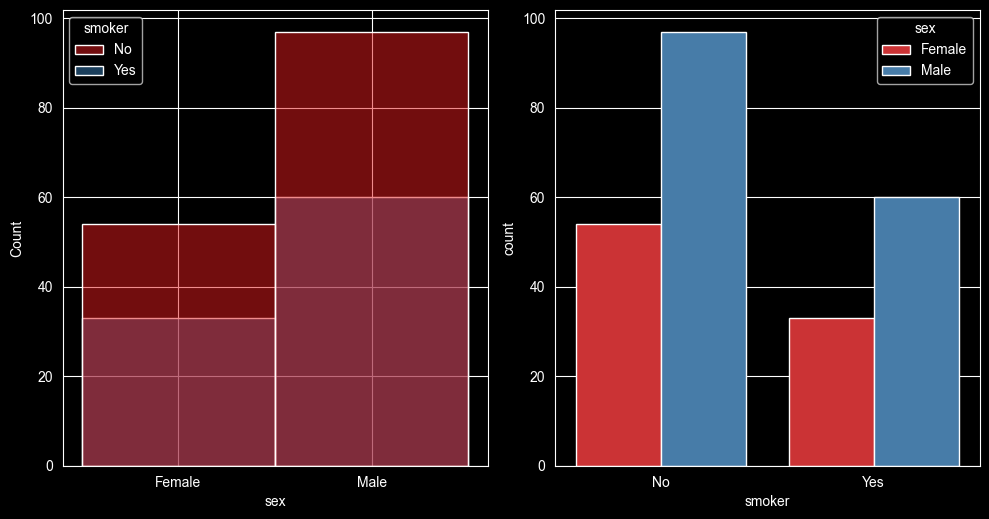

In [218]:
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
sns.histplot(data=df,x='sex',hue='smoker',palette='Set1')
plt.subplot(2,2,2)


plt.subplot(2,2,2)
sns.countplot(data=df, x='smoker',hue='sex',palette='Set1')


plt.tight_layout()
plt.show()

Removing outlier from total_bill , tips using capping

In [219]:
from feature_engine.outliers import  Winsorizer, OutlierTrimmer
import  numpy as np

In [220]:
capper = Winsorizer( # Outlier Trimmer for trimming method
    capping_method='iqr',  # Options: 'iqr', 'gaussian', 'quantiles', 'mad'
    tail='both',           # Options: 'both', 'left', 'right'
    fold=1.5,              # Multiplier threshold for the capping method
    variables=['total_bill', 'tip'] # Specify columns (if None, it picks all numeric cols)
)

capper.fit(df)
df = capper.transform(df)

In [221]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01000,Female,No,Sun,Dinner,2
1,10.34,1.66000,Male,No,Sun,Dinner,3
2,21.01,3.50000,Male,No,Sun,Dinner,3
3,23.68,3.31000,Male,No,Sun,Dinner,2
4,24.59,3.61000,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.90625,Male,No,Sat,Dinner,3
240,27.18,2.00000,Female,Yes,Sat,Dinner,2
241,22.67,2.00000,Male,Yes,Sat,Dinner,2
242,17.82,1.75000,Male,No,Sat,Dinner,2


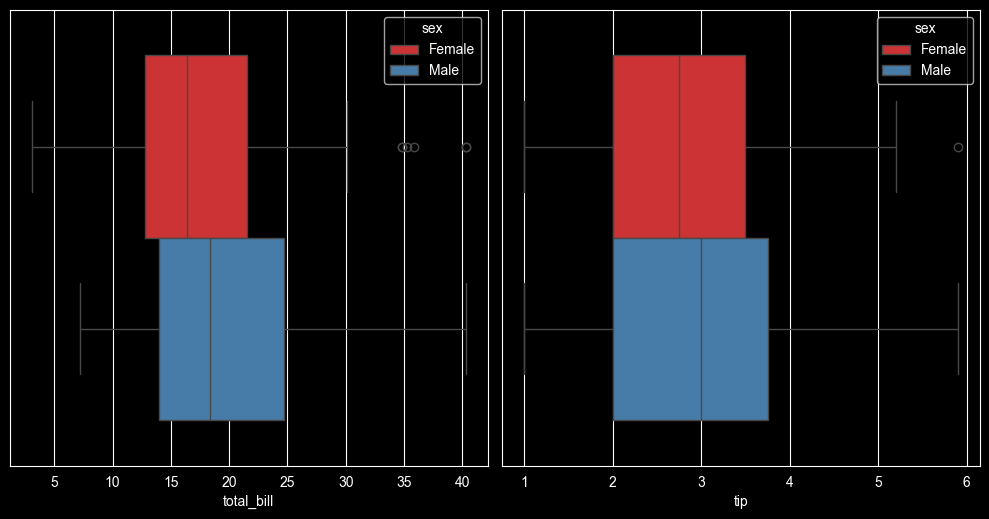

In [222]:
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
sns.boxplot(data=df, x='total_bill',hue='sex',palette='Set1')
plt.subplot(2,2,2)


plt.subplot(2,2,2)
sns.boxplot(data=df, x='tip',hue='sex',palette='Set1')


plt.tight_layout()
plt.show()

Applying Z score method  for capping and tailing both doing this manually
z = value-mean/std

In [223]:
df.sample(5)

,total_bill,tip,sex,smoker,day,time,size
66,16.45,2.47,Female,No,Sat,Dinner,2
194,16.58,4.00,Male,Yes,Thur,Lunch,2
124,12.48,2.52,Female,No,Thur,Lunch,2
73,25.28,5.00,Female,Yes,Sat,Dinner,2
138,16.00,2.00,Male,Yes,Thur,Lunch,2


In [224]:
class autooutlier():
    def __init__(self,upper_limit,lower_limit):
        self.upper_limit = upper_limit
        self.lower_limit = lower_limit


    def fit(self, df):
        self.df = df
        upper_limit = self.upper_limit
        lower_limit = self.lower_limit

        x = df.where(df >=upper_limit,
                      df[df<upper_limit]
                      .where(df <=lower_limit,
                             df[df>lower_limit]
                       )
                )

        return x





In [225]:
mean = df[['total_bill']].mean()
std = df[['total_bill']].std()
z_threshold = 3
z = autooutlier(mean + (z_threshold * std),mean - (z_threshold * std))
df[['total_bill']] = z.fit(df[['total_bill']])

<Axes: xlabel='total_bill'>

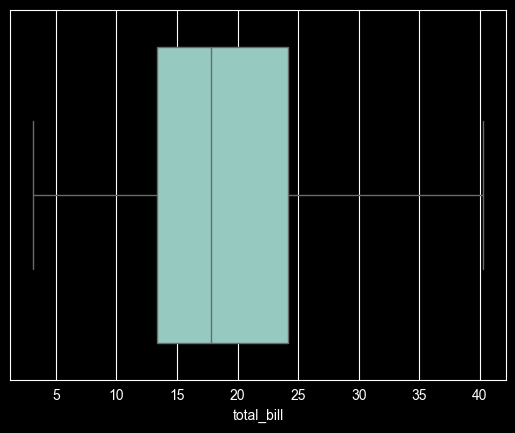

In [226]:
sns.boxplot(data=df, x='total_bill',)

In [227]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01000,Female,No,Sun,Dinner,2
1,10.34,1.66000,Male,No,Sun,Dinner,3
2,21.01,3.50000,Male,No,Sun,Dinner,3
3,23.68,3.31000,Male,No,Sun,Dinner,2
4,24.59,3.61000,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.90625,Male,No,Sat,Dinner,3
240,27.18,2.00000,Female,Yes,Sat,Dinner,2
241,22.67,2.00000,Male,Yes,Sat,Dinner,2
242,17.82,1.75000,Male,No,Sat,Dinner,2


In [228]:
df[['total_bill']].skew()

total_bill    0.842031
dtype: float64

<Axes: xlabel='total_bill', ylabel='Count'>

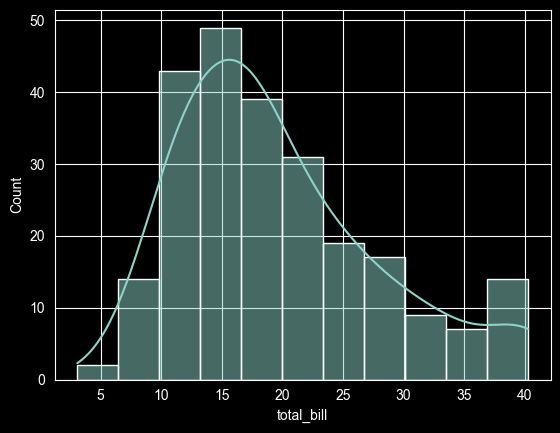

In [229]:
sns.histplot(data=df,x='total_bill',kde=True)

In [230]:
df['total_bill'] = np.sqrt(df['total_bill'])

In [231]:
df[['total_bill']].skew()

total_bill    0.383526
dtype: float64

<Axes: xlabel='total_bill', ylabel='Count'>

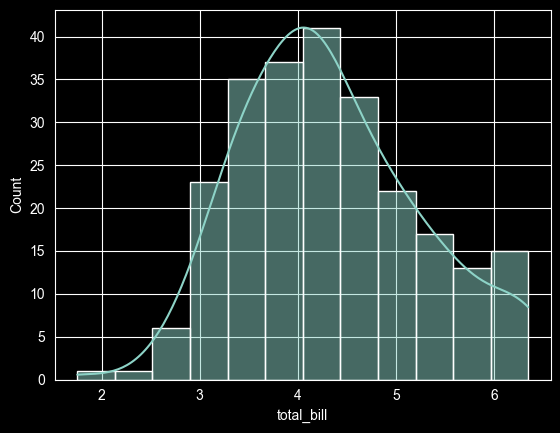

In [232]:
sns.histplot(data=df,x='total_bill',kde=True)